[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_hedonic/BA_L7_hedonic.ipynb)

# BA_L7_hedonic: Hedonic index versus median price on simulated art sales

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Composition bias in a boom: 3,600 simulated sales of digital artworks over 12 quarters with a known true price index; a time-dummy hedonic regression controlling for rarity, artist and size is compared with the median sale price index by their RMSE in logs.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Method

Each non-fungible token (NFT) or digital artwork is unique and trades rarely, so a median sale price mixes price changes with
**composition** changes. The time-dummy hedonic regression on all sales $n$ in quarters $t = 0, \dots, T$,

$$ \ln P_{n} = \sum_{t=1}^{T}\delta_t D_{n,t} + \mathbf x_n'\boldsymbol\beta + \varepsilon_n, \qquad I_t = 100\,e^{\hat\delta_t}, $$

controls for the characteristics $\mathbf x_n$ (rarity, known artist, size), so $\hat\delta_t$ is a quality-adjusted log price level.
The simulation has 12 quarters with 300 sales each and a known true index (a boom and a bust); in the boom (quarters 2–5) more
low-rarity works by unknown artists are sold. Both indices are scored by their root mean squared error (RMSE) in logs against the true index.

In [5]:
import statsmodels.formula.api as smf

rng = np.random.default_rng(42)
TQ = 12
true = np.array([0, 0.25, 0.6, 1.1, 1.5, 1.2, 0.5, -0.1, -0.3, -0.2, 0.0, 0.1])     # true log index
rows = []
for t in range(TQ):
    n = 300
    boom = 1 if 2 <= t <= 5 else 0
    rarity = rng.beta(2, 5 + 4 * boom, n)                  # in the boom: lower rarity
    known = rng.random(n) < (0.35 - 0.2 * boom)            # in the boom: fewer known artists
    size = rng.normal(0, 1, n)
    lp = 6 + true[t] + 2.5 * rarity + 1.2 * known + 0.1 * size + rng.normal(0, 0.6, n)
    rows.append(pd.DataFrame(dict(q=t, lp=lp, rarity=rarity, known=known.astype(int), size=size)))
DS = pd.concat(rows)
mh = smf.ols('lp ~ C(q) + rarity + known + size', data=DS).fit(cov_type='HC1')
hed = np.r_[0, [mh.params[f'C(q)[T.{t}]'] for t in range(1, TQ)]]
se = np.r_[0, [mh.bse[f'C(q)[T.{t}]'] for t in range(1, TQ)]]
med = np.log(DS.groupby('q')['lp'].apply(lambda x: np.exp(x).median()).values)
med = med - med[0]
print(f'Simulated sales: {len(DS)}')
print(f"Estimated effect of rarity {mh.params['rarity']:.2f} (true 2.5), of a known artist {mh.params['known']:.2f} (true 1.2)")
print(pd.DataFrame({'true log index': true, 'hedonic': hed, 'median price': med}).round(2).T.to_string())
print(f'RMSE in logs: hedonic {np.sqrt(np.mean((hed - true) ** 2)):.2f}, median {np.sqrt(np.mean((med - true) ** 2)):.2f}')
print(f'Peak (quarter 4), index with quarter 0 = 100: true {100 * np.exp(true[4]):.0f}, hedonic {100 * np.exp(hed[4]):.0f}, '
      f'median {100 * np.exp(med[4]):.0f} ({100 * (1 - np.exp(med[4] - true[4])):.0f}% below the true value)')

Simulated sales: 3600
Estimated effect of rarity 2.52 (true 2.5), of a known artist 1.20 (true 1.2)
                 0     1     2     3     4     5     6     7     8     9     10    11
true log index  0.0  0.25  0.60  1.10  1.50  1.20  0.50 -0.10 -0.30 -0.20  0.00  0.10
hedonic         0.0  0.30  0.69  1.21  1.55  1.28  0.63 -0.01 -0.18 -0.13  0.09  0.15
median price    0.0  0.48  0.31  0.76  1.15  0.80  0.69  0.09 -0.11  0.04  0.05  0.34
RMSE in logs: hedonic 0.09, median 0.25
Peak (quarter 4), index with quarter 0 = 100: true 448, hedonic 469, median 315 (30% below the true value)


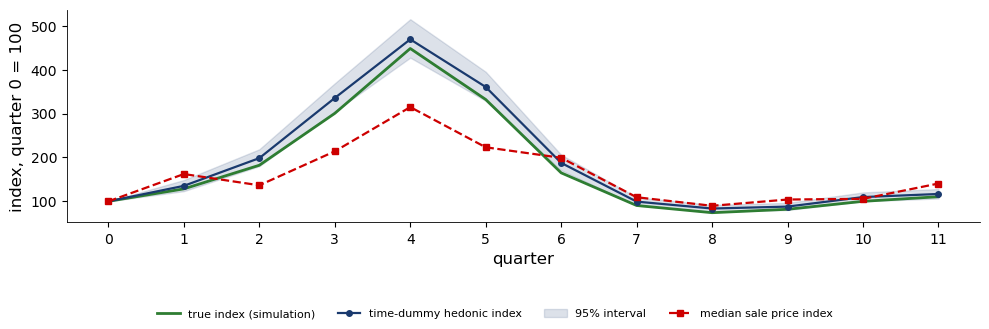

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.3))
q = np.arange(TQ)
ax.plot(q, 100 * np.exp(true), color=GREEN, lw=2, label='true index (simulation)')
ax.plot(q, 100 * np.exp(hed), color=BLUE, lw=1.6, marker='o', ms=4, label='time-dummy hedonic index')
ax.fill_between(q, 100 * np.exp(hed - 1.96 * se), 100 * np.exp(hed + 1.96 * se), color=BLUE, alpha=0.15, label='95% interval')
ax.plot(q, 100 * np.exp(med), color=RED, lw=1.6, ls='--', marker='s', ms=4, label='median sale price index')
ax.set_xlabel('quarter'); ax.set_ylabel('index, quarter 0 = 100'); ax.set_xticks(q)
slide_fig(fig, 'ba_l7_hedonic', 0.13, ncol=4)

**How to read it.** The hedonic index tracks the true index; the median index understates the boom, because cheaper works flood the market.